## Modeling Dataset Construction

This notebook builds and evaluates predictive models for response-time estimation.

### Objectives
- Construct a leakage-aware feature set
- Use time-based train/validation/test splits
- Benchmark CatBoost against simple baselines
- Improve generalization through feature design and tuning


In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns, datetime as dt, numpy as np, glob, os
import sys
!{sys.executable} -m pip install pyarrow

pd.set_option('display.max_columns', None)

DRIVE_URL = "https://drive.google.com/uc?export=download&id=1F06NYKBF8loCTPEaPT_qIhcQy2T5iM6H"
DATA_PATH = "data.csv"

# Preferred: local multi-file raw data. Fallback: single downloaded CSV.
all_files = sorted(glob.glob("csv_files/get_it_done_requests_closed_20*_datasd.csv"))

if all_files:
    print(f"Loading {len(all_files)} local annual CSV files from csv_files/...")
    df_list = []
    for file in all_files:
        year = file.split('_')[-2]
        df = pd.read_csv(file)
        if 'year' not in df.columns:
            df['year'] = year
        df_list.append(df)
        print(f"Loaded {year}: {len(df)} rows")
    all_data = pd.concat(df_list, ignore_index=True)
else:
    if not os.path.exists(DATA_PATH):
        print("No local annual CSV files found. Attempting Google Drive download...")
        try:
            import gdown
            gdown.download(DRIVE_URL, DATA_PATH, quiet=False)
        except Exception as e:
            raise RuntimeError(
                "Could not load local CSVs and automatic download failed. "
                "Install gdown (`pip install gdown`) or place data.csv in project root."
            ) from e

    all_data = pd.read_csv(DATA_PATH, low_memory=False)
    if 'year' not in all_data.columns and 'date_requested' in all_data.columns:
        all_data['date_requested'] = pd.to_datetime(all_data['date_requested'], errors='coerce')
        all_data['year'] = all_data['date_requested'].dt.year
    print(f"Loaded single-file dataset: {len(all_data):,} rows")

# Data Cleaning
master = all_data[all_data["status"] != "Referred"].drop(columns=["referred"])
# Clean neighborhood names
master["comm_plan_name"] = master["comm_plan_name"].str.title()
def clean_case_type(case):
    if not isinstance(case,str):
        return case

    if "graffiti" in case.lower():
        return "Graffiti"
    return case

#Drop rows where service_name == "Other"(vague)
before_rows = len(master)
master = master[master["service_name"] != "Other"]
print(f"✓ Dropped 'Other' service type: {before_rows - len(master):,} rows")
#Remove invalid case_age_days (negative values)
before_rows = len(master)
master = master[master["case_age_days"] >= 0]
print(f"✓ Removed invalid case_age_days: {before_rows - len(master):,} rows")

#Remove duplicates (same service_request_id)
before_rows = len(master)
master = master[~master['service_request_id'].duplicated()]
print(f"✓ Removed duplicates: {before_rows - len(master):,} rows")

# keep consistent case types
master["service_name"] = master["service_name"].apply(clean_case_type)




[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip
Loading 10 local annual CSV files from csv_files/...
Loaded 2016: 33631 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/1218280786.py:18: DtypeWarning: Columns (7,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2017: 139500 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/1218280786.py:18: DtypeWarning: Columns (2,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2018: 169603 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/1218280786.py:18: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2019: 302699 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/1218280786.py:18: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2020: 280071 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/1218280786.py:18: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2021: 359879 rows
Loaded 2022: 349241 rows
Loaded 2023: 432431 rows
Loaded 2024: 429933 rows
Loaded 2025: 378618 rows
✓ Dropped 'Other' service type: 26,693 rows
✓ Removed invalid case_age_days: 670 rows
✓ Removed duplicates: 17 rows


## Feature Engineering (Initial)

This section creates baseline temporal, text, and request-context features for first-pass modeling.


In [2]:
# Adding Features for modeling

model_data = master.copy()
#handles outliers
model_data = model_data[model_data["case_age_days"]<= 365*2]
# Continue with model_data (already filtered for outliers)
# Continue with model_data (already filtered for outliers)
print("\n=== FEATURE ENGINEERING ON MODEL_DATA ===")
print(f"Starting with {len(model_data):,} rows (after outlier removal)")

# Parse dates
model_data['date_requested'] = pd.to_datetime(model_data['date_requested'], errors='coerce')

# Temporal features
model_data['year'] = model_data['date_requested'].dt.year
model_data['month'] = model_data['date_requested'].dt.month
model_data['day_of_week'] = model_data['date_requested'].dt.dayofweek
model_data['hour'] = model_data['date_requested'].dt.hour
model_data['quarter'] = model_data['date_requested'].dt.quarter
model_data['is_weekend'] = (model_data['day_of_week'] >= 5).astype(int)

# Location features
model_data['is_district_56'] = model_data['council_district'].isin([5, 6]).astype(int)

# Fill missing council_district with 0 (Unknown)
missing_district = model_data['council_district'].isna().sum()
model_data['council_district'] = model_data['council_district'].fillna(0)
print(f"✓ Filled {missing_district:,} missing council_districts with 0 (Unknown)")

# Request type features
infrastructure_types = [
    'Pothole',
    'Street Light Maintenance',
    'Traffic Signal Issue',
    'Traffic Signal Timing',
    'Traffic Sign Maintenance',
    'Sidewalk Repair Issue',
    'Pavement Maintenance',
    'Street Repair',
    'Curb Repair'
]
model_data['is_infrastructure'] = model_data['service_name'].isin(infrastructure_types).astype(int)
model_data['is_followup'] = model_data['service_request_parent_id'].notna().astype(int)

# Text features
model_data['description_length'] = model_data['public_description'].str.len().fillna(0)
model_data['has_description'] = (model_data['description_length'] > 0).astype(int)

# Log-transformed target for regression
model_data['log_wait'] = np.log1p(model_data['case_age_days'])

# Target variable for classification
model_data['response_category'] = pd.cut(
    model_data['case_age_days'],
    bins=[0, 3, 7, 21, 90,730],
    labels=['very_fast', 'fast', 'medium', 'slow',"super_slow"],
    include_lowest=True
)

print("✓ Created all features")
# Dropping columns
columns_to_drop = [
    'date_closed',  # Already have case_age_days
    'service_request_id',  # Just an ID
    'service_request_parent_id',  # Used for is_followup feature
    'public_description',  # Used for description_length
    'sap_notification_number',  # Internal ID
    'specify_the_issue',  # Too many missing
    'public_url',  # Not useful for prediction
    'iamfloc',  # Internal code
    'floc',  # Internal code
    'park_name',  # Too many missing
]
model_data = model_data.drop(columns=columns_to_drop)

model_data['has_service_name_detail'] = model_data['service_name_detail'].notna().astype(int)
print(f"✓ Dropped {len(columns_to_drop)} unnecessary columns")

# Summary
print("\n=== MODEL DATA SUMMARY ===")
print(f"Total rows: {len(model_data):,}")
print(f"Total columns: {len(model_data.columns)}")

print(f"\nTarget variable (case_age_days) statistics:")
print(model_data['case_age_days'].describe())

print(f"\nResponse category distribution:")
print(model_data['response_category'].value_counts())

print(f"\nKey features created:")
print(f"  - Temporal: year, month, day_of_week, hour, quarter, is_weekend")
print(f"  - Location: is_district_56, council_district (0 = Unknown)")
print(f"  - Request type: is_infrastructure, is_followup")
print(f"  - Text: description_length, has_description")
print(f"  - Target: response_category (very_fast/fast/medium/slow)")

# Check for any remaining missing values in key columns
print("\n=== MISSING VALUES CHECK ===")
key_cols = ['service_name', 'council_district', 'case_age_days', 'year', 'month', 'day_of_week']
missing_summary = model_data[key_cols].isna().sum()
print(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "No missing values in key columns ✓")

print(f"\n✓ 'model_data' ready with {len(model_data):,} rows and {len(model_data.columns)} columns")
print(f"✓ Original 'master' dataframe preserved for EDA")



=== FEATURE ENGINEERING ON MODEL_DATA ===
Starting with 2,453,645 rows (after outlier removal)
✓ Filled 32,066 missing council_districts with 0 (Unknown)
✓ Created all features
✓ Dropped 10 unnecessary columns

=== MODEL DATA SUMMARY ===
Total rows: 2,453,645
Total columns: 28

Target variable (case_age_days) statistics:
count    2.453645e+06
mean     3.295286e+01
std      8.362735e+01
min      0.000000e+00
25%      1.000000e+00
50%      5.000000e+00
75%      2.200000e+01
max      7.300000e+02
Name: case_age_days, dtype: float64

Response category distribution:
response_category
very_fast     1067828
medium         423695
slow           399743
fast           340060
super_slow     222319
Name: count, dtype: int64

Key features created:
  - Temporal: year, month, day_of_week, hour, quarter, is_weekend
  - Location: is_district_56, council_district (0 = Unknown)
  - Request type: is_infrastructure, is_followup
  - Text: description_length, has_description
  - Target: response_category (v

## Feature Engineering (Refinement Iterations)

This section adds and tests stronger features after baseline evaluation,(mainly for service_name_detail_clean) including cleaned categorical fields and interaction/context features.


In [3]:
import numpy as np
import re

model_data = model_data.copy()

def norm_text(x):
    x = str(x)
    x = x.strip().lower()
    x = re.sub(r"\s+", " ", x)   # collapse repeated spaces
    return x

# Raw strings
s_raw = model_data["service_name"].fillna("Missing").astype(str)
d_raw = model_data["service_name_detail"].fillna("Missing").astype(str)

# Normalized strings for matching only
s_norm = s_raw.map(norm_text)
d_norm = d_raw.map(norm_text)

# Same-as-service flag using normalized text
same_mask = d_norm == s_norm

# Build cleaned detail
model_data["service_name_detail_clean"] = np.where(
    same_mask,
    "SameAsService",
    d_raw
).astype(str)

# Rare bucket after same-as collapse
counts = model_data["service_name_detail_clean"].value_counts()
rare = counts[counts < 150].index
model_data["service_name_detail_clean"] = model_data["service_name_detail_clean"].replace(rare, "Other")

# Extra-detail indicator
model_data["has_extra_detail"] = (~same_mask).astype(int)

print(model_data["service_name_detail_clean"].value_counts().head(20))



service_name_detail_clean
Missing                                   851279
SameAsService                             650084
72 Hour Violation                         286225
Graffiti Removal                          118054
Parking Zone Violation                     49997
STREET LIGHT OUT                           46364
Potential Missed Collection                31723
LIGHTS OUT                                 22466
Other                                      22413
Container Left Out                         20556
CONCRETE SIDEWALK REPAIR ISSUE             20082
LIGHTS ON FLASH                            16853
SWPP - Storm Water Polution Prevention     14604
Red Zone                                   14586
Graffiti Removal - Commercial              13085
DRAIN INLET                                11635
EVALUATE TREE FOR REMOVAL                   9118
Sidewalk                                    9078
Commercial Property                         8903
Graffiti                                   

In [4]:
model_data = model_data.copy()

# 1) Prep
model_data["date_requested"] = pd.to_datetime(model_data["date_requested"], errors="coerce")
model_data = model_data.dropna(subset=["date_requested"]).sort_values("date_requested").reset_index(drop=True)

model_data["service_name"] = model_data["service_name"].fillna("Missing").astype(str)
model_data["comm_plan_name"] = model_data["comm_plan_name"].fillna("Missing").astype(str)

# helper for rolling counts
model_data["_one"] = 1.0

# 2) 30-day workload features (leakage-safe: prior window only)
# Build each rolling feature within group and return values aligned to original row index.
model_data["workload_30d_service"] = (
    model_data.groupby("service_name", group_keys=False)
    .apply(
        lambda g: pd.Series(
            g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
            index=g.index,
        )
    )
    .fillna(0)
)

model_data["workload_30d_neighborhood"] = (
    model_data.groupby("comm_plan_name", group_keys=False)
    .apply(
        lambda g: pd.Series(
            g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
            index=g.index,
        )
    )
    .fillna(0)
)

model_data["workload_30d_service_neighborhood"] = (
    model_data.groupby(["service_name", "comm_plan_name"], group_keys=False)
    .apply(
        lambda g: pd.Series(
            g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
            index=g.index,
        )
    )
    .fillna(0)
)

# 3) Interaction feature
model_data["service_x_neighborhood"] = (
    model_data["service_name"] + " | " + model_data["comm_plan_name"]
)

# optional: collapse rare interaction categories
vc = model_data["service_x_neighborhood"].value_counts()
rare = vc[vc < 100].index
model_data["service_x_neighborhood"] = model_data["service_x_neighborhood"].replace(rare, "Other")

# cleanup
model_data = model_data.drop(columns=["_one"])



/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/236868000.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/236868000.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_89992/236868000.py:39: FutureWarning: DataFrameGroupBy.apply operated on the grouping col

## Quick Correlation Screening using Heatmap

This section provides a quick directional check of numerical associations with `log_wait`.

It is used for feature intuition only; final model decisions are based on validation/test performance.


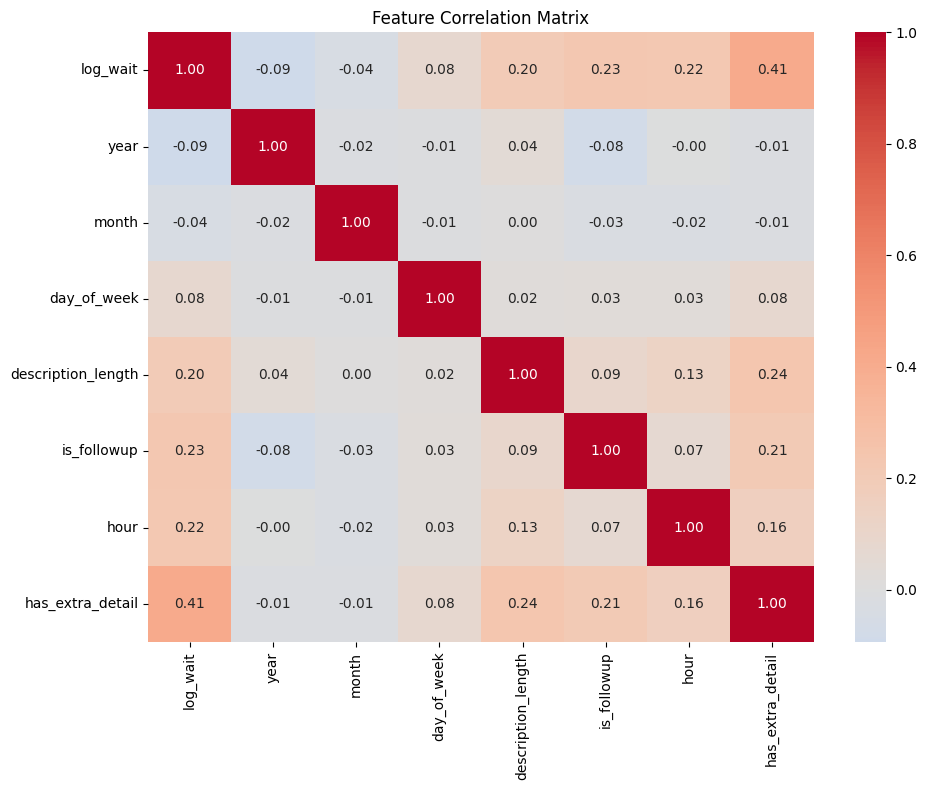


=== CORRELATION WITH RESPONSE TIME ===
log_wait              1.000000
has_extra_detail      0.414091
is_followup           0.229216
hour                  0.221146
description_length    0.202287
day_of_week           0.077306
month                -0.042736
year                 -0.093815
Name: log_wait, dtype: float64


In [5]:
# Create potential features first
#model_data = model_data[(model_data["year"]=="2024") | (model_data["year"]=="2025")]
# Correlation matrix for numerical features
cat_df = model_data[model_data["year"] >= 2023]
numerical_features = ['log_wait', 'year', 'month', 
                      'day_of_week', "description_length","is_followup",'hour', 'has_extra_detail']

corr_data = cat_df[numerical_features].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

# Print correlations with target
print("\n=== CORRELATION WITH RESPONSE TIME ===")
print(corr_data['log_wait'].sort_values(ascending=False))

## CatBoost Modeling

CatBoost is used to handle mixed numerical/categorical tabular data with minimal manual encoding and strong baseline performance on operational datasets.


## Validation Strategy

A strict time-based split is used to mimic deployment conditions and avoid future-to-past leakage:
- Train: earlier period
- Validation: intermediate period
- Test: most recent period


## Train/Validation/Test Feature Assembly

This section defines numeric/categorical feature lists, applies consistent categorical preprocessing, and builds model matrices for each split.


In [6]:

x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'service_name_detail_clean', 'case_record_type', "service_x_neighborhood"]
x_numerical.sort()
x_cat.sort()
y = 'log_wait'
x_total = x_numerical + x_cat
cat_df = cat_df.copy()
for c in x_cat:
    cat_df[c] = cat_df[c].fillna('Missing').astype(str)

train_df = cat_df[cat_df['date_requested'] < '2025-01-01'].copy()
valid_df = cat_df[(cat_df['date_requested'] >= '2025-01-01') & (cat_df['date_requested'] < '2025-07-01')].copy()
test_df = cat_df[cat_df['date_requested'] >= '2025-07-01'].copy()

print(f'train_df shape is {train_df.shape} | {len(train_df)/len(cat_df)*100}%')
print(f'valid_df shape is {valid_df.shape} | {len(valid_df)/len(cat_df)*100}%')
print(f'test_df shape is {test_df.shape} | {len(test_df)/len(cat_df)*100}%')

X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]

train_df shape is (764981, 34) | 70.42675067758661%
valid_df shape is (163796, 34) | 15.079616427056328%
test_df shape is (157431, 34) | 14.49363289535706%


In [9]:
from catboost import CatBoostRegressor
cat_boost = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,
    
)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_log = cat_model.predict(X_test)



0:	learn: 1.5501659	test: 1.4704787	best: 1.4704787 (0)	total: 176ms	remaining: 2m 55s
100:	learn: 0.9988709	test: 1.0550233	best: 1.0525353 (54)	total: 10.5s	remaining: 1m 33s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 1.052535344
bestIteration = 54

Shrink model to first 55 iterations.


## Baseline CatBoost Results

This section reports baseline CatBoost performance before extensive tuning and feature expansion.


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['RMSE'][-5:])

true_log = y_test.values

pred_days = np.expm1(results_log)
true_days = np.expm1(true_log)
## Day results

r2_days = r2_score(true_days, pred_days)
rmse_days = np.sqrt(mean_squared_error(true_days, pred_days))
mae_days = mean_absolute_error(true_days, pred_days)

##log results
r2_log = r2_score(true_log, results_log)
rmse_log = np.sqrt(mean_squared_error(true_log, results_log))
mae_log = mean_absolute_error(true_log, results_log)

print(f"R^2 in Days is {np.round(r2_days, 3)}")
print(f"RSME in Days is {np.round(rmse_days, 3)}")
print(f"MAE in Days is {np.round(mae_days, 3)} days")
print()
print(f"R^2 Logged is {np.round(r2_log, 3)}")
print(f"RSME Logged is {np.round(rmse_log, 3)}")
print(f"MAE Logged is {np.round(mae_log, 3)}")

# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


dict_keys(['learn', 'validation'])
[1.0550232773641297, 1.056858553859032, 1.0564425416851584, 1.0567943188121367, 1.0568357938073674]
R^2 in Days is 0.241
RSME in Days is 17.322
MAE in Days is 8.299 days

R^2 Logged is 0.446
RSME Logged is 0.979
MAE Logged is 0.726


,Feature,Importance
9,case_origin,28.870911
14,service_name_detail_clean,28.410644
13,service_name,17.521145
10,case_record_type,13.499195
15,service_x_neighborhood,3.513271
8,year,2.078158
3,is_followup,2.060056
6,workload_30d_service,1.880694
4,month,1.237227
2,hour,0.635719


## Median Baseline

A naive median predictor is used as a reference point to verify that the model provides meaningful lift over a simple baseline.


In [11]:

train_median = train_df['case_age_days'].median()
prediction_median = np.full(len(y_test), train_median)

median_r2_days = r2_score(true_days, prediction_median)
median_rmse_days = np.sqrt(mean_squared_error(true_days, prediction_median))
median_mae_days = mean_absolute_error(true_days, prediction_median)

print(f"R^2 in Days is {np.round(median_r2_days, 3)}")
print(f"RSME in Days is {np.round(median_rmse_days, 3)}")
print(f"MAE in Days is {np.round(median_mae_days, 3)} days")

R^2 in Days is -0.091
RSME in Days is 20.769
MAE in Days is 9.709 days


## Hyperparameter Optimization (Optuna)

This section tunes CatBoost hyperparameters on the validation split while preserving the fixed time-based test set for final evaluation.


In [22]:
import optuna
import json
from pathlib import Path
# objective does the training and you are returning the parameter that you want to be optimized
def objective(trial):
    params = {
        "loss_function":"RMSE",
        "eval_metric":'RMSE',
        
        "iterations": trial.suggest_int('iterations', 500, 4000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 3,10),
        
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 100.0, log=True),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 1000),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10.0, log=True),

        'random_seed': 42,
        'od_type': 'Iter',
        'od_wait' :50,
        'verbose':False
        
    }
    optuna_model = CatBoostRegressor(**params)

    optuna_model.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

    optuna_pred_valid = optuna_model.predict(X_valid)
    rmse_valid = np.sqrt(mean_squared_error(y_valid, optuna_pred_valid))
    return rmse_valid # want to minimize this

study = optuna.create_study(direction='minimize', study_name="cat_boost_logwait_tune")
study.optimize(objective, n_trials=15, show_progress_bar=True)

print('Best value(RMSE Log) is: ', study.best_value)
print('Best Params:')
for key, value in study.best_params.items():
    print(f"{key}: {value}")

out = {
    "best_value": study.best_value,
    "best_params": study.best_params,
    "direction": study.direction.name,
    "n_trials": len(study.trials),
}

Path("models").mkdir(exist_ok=True)
with open("models/optuna_best_params.json", "w") as f:
    json.dump(out, f, indent=2)

print("Saved to models/optuna_best_params.json")


[I 2026-03-24 16:21:14,729] A new study created in memory with name: cat_boost_logwait_tune
Best trial: 0. Best value: 1.05603:   7%|▋         | 1/15 [00:06<01:28,  6.33s/it]

[I 2026-03-24 16:21:21,058] Trial 0 finished with value: 1.0560300677250647 and parameters: {'iterations': 1904, 'learning_rate': 0.05797256608603932, 'depth': 4, 'l2_leaf_reg': 3.29421424158078, 'min_data_in_leaf': 622, 'subsample': 0.7647230733953818, 'random_strength': 0.0016303974100616053}. Best is trial 0 with value: 1.0560300677250647.


Best trial: 0. Best value: 1.05603:  13%|█▎        | 2/15 [00:23<02:48, 12.93s/it]

[I 2026-03-24 16:21:38,611] Trial 1 finished with value: 1.0567575077922349 and parameters: {'iterations': 1678, 'learning_rate': 0.012766128298795872, 'depth': 4, 'l2_leaf_reg': 8.143106339299266, 'min_data_in_leaf': 440, 'subsample': 0.8440459938015322, 'random_strength': 1.1983177239885963}. Best is trial 0 with value: 1.0560300677250647.


Best trial: 2. Best value: 1.05581:  20%|██        | 3/15 [00:30<02:00, 10.03s/it]

[I 2026-03-24 16:21:45,199] Trial 2 finished with value: 1.0558134609379488 and parameters: {'iterations': 1551, 'learning_rate': 0.03657003639876334, 'depth': 3, 'l2_leaf_reg': 27.887406362959553, 'min_data_in_leaf': 683, 'subsample': 0.7869530567095026, 'random_strength': 0.3368100570605173}. Best is trial 2 with value: 1.0558134609379488.


... (20 outputs left out)

Best trial: 8. Best value: 1.03945:  93%|█████████▎| 14/15 [03:11<00:13, 13.34s/it]

[I 2026-03-24 16:24:25,902] Trial 13 finished with value: 1.0430670199717966 and parameters: {'iterations': 2365, 'learning_rate': 0.05643471913930481, 'depth': 8, 'l2_leaf_reg': 9.967471543209117, 'min_data_in_leaf': 253, 'subsample': 0.6950186367565947, 'random_strength': 2.2335898438515582}. Best is trial 8 with value: 1.039448178776324.


Best trial: 8. Best value: 1.03945: 100%|██████████| 15/15 [03:34<00:00, 14.27s/it]

[I 2026-03-24 16:24:48,730] Trial 14 finished with value: 1.0420954917739575 and parameters: {'iterations': 715, 'learning_rate': 0.024002793550709996, 'depth': 9, 'l2_leaf_reg': 32.25824843410318, 'min_data_in_leaf': 276, 'subsample': 0.9202545206966564, 'random_strength': 8.78664642630929}. Best is trial 8 with value: 1.039448178776324.
Best value(RMSE Log) is:  1.039448178776324
Best Params:
iterations: 2683
learning_rate: 0.012026068919134016
depth: 10
l2_leaf_reg: 26.01549806800122
min_data_in_leaf: 412
subsample: 0.7723299903439417
random_strength: 1.3487693201420443
Saved to models/optuna_best_params.json


## Optimized Model Results and Tradeoffs

Optimization improves performance, but feature quality and leakage-safe context features are the primary drivers of larger gains in this project.


## Stronger Feature Development

### Changes Introduced
- Cleaned `service_name_detail` categories
- Added service-context fields (for example, `case_record_type`)
- Added interaction/context features and rolling workload signals

### Challenges Encountered
- Categorical type errors (float/NaN in `cat_features`)
- Rolling-window index alignment issues in pandas
- Run-to-run variance caused by non-deterministic row ordering and threading

### Resolutions
- Enforced string casting and explicit missing tokens for categorical features
- Rebuilt rolling features with index-safe alignment
- Applied deterministic sorting before feature generation and split construction

### Current Documented Outcome
Feature engineering delivered the largest gains relative to baseline and reduced test error meaningfully.


In [23]:
best_params = {
    **study.best_params,
    'random_seed':42,
    'eval_metric': 'RMSE',
    'loss_function':'RMSE',
    'od_type':'Iter',
    'od_wait':100,
    "verbose":100
}


best_cat_model = CatBoostRegressor(**best_params)
best_cat_model.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

true_log_opt = y_test.values
true_days_opt = np.expm1(true_log_opt)

best_pred_log = best_cat_model.predict(X_test)
best_pred_days = np.expm1(best_pred_log)


best_r2_days = r2_score(true_days_opt, best_pred_days)
best_rmse_days = np.sqrt(mean_squared_error(true_days_opt, best_pred_days))
best_mae_days = mean_absolute_error(true_days_opt, best_pred_days)

##log results
best_r2_log = r2_score(true_log_opt, best_pred_log)
best_rmse_log = np.sqrt(mean_squared_error(true_log_opt, best_pred_log))
best_mae_log = mean_absolute_error(true_log_opt, best_pred_log)

print(f"R^2 in Days is {np.round(best_r2_days, 3)}")
print(f"RSME in Days is {np.round(best_rmse_days, 3)}")
print(f"MAE in Days is {np.round(best_mae_days, 3)} days")
print()
print(f"R^2 Logged is {np.round(best_r2_log, 3)}")
print(f"RSME Logged is {np.round(best_rmse_log, 3)}")
print(f"MAE Logged is {np.round(best_mae_log, 3)}")

best_feature_importance = best_cat_model.get_feature_importance()

best_feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":best_feature_importance}).sort_values('Importance', ascending=False)
best_feature_ranking

0:	learn: 1.5817702	test: 1.5023619	best: 1.5023619 (0)	total: 109ms	remaining: 4m 51s
100:	learn: 1.0814668	test: 1.0774885	best: 1.0774885 (100)	total: 10.9s	remaining: 4m 39s
200:	learn: 0.9998351	test: 1.0409068	best: 1.0409068 (200)	total: 23.6s	remaining: 4m 51s
300:	learn: 0.9764448	test: 1.0399660	best: 1.0394482 (244)	total: 37.6s	remaining: 4m 57s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 1.03944818
bestIteration = 244

Shrink model to first 245 iterations.
R^2 in Days is 0.258
RSME in Days is 17.127
MAE in Days is 8.001 days

R^2 Logged is 0.485
RSME Logged is 0.944
MAE Logged is 0.698


,Feature,Importance
9,case_origin,24.331742
14,service_name_detail_clean,23.143449
13,service_name,16.109181
10,case_record_type,12.666442
8,year,5.317656
4,month,5.272863
6,workload_30d_service,4.477354
3,is_followup,2.932157
15,service_x_neighborhood,2.225803
2,hour,1.048655


## Notebook Summary

CatBoost outperforms naive baseline prediction on the held-out time split.
Most performance gains came from improved feature design and leakage-aware preprocessing, with tuning providing incremental gains.


In [12]:

x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'service_name_detail_clean', 'case_record_type', "service_x_neighborhood"]
x_numerical.sort()
x_cat.sort()
y = 'log_wait'
x_total = x_numerical + x_cat


X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]

from catboost import CatBoostRegressor
cat_boost = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,
    
)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_log = cat_model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['RMSE'][-5:])

true_log = y_test.values

pred_days = np.expm1(results_log)
true_days = np.expm1(true_log)
## Day results

r2_days = r2_score(true_days, pred_days)
rmse_days = np.sqrt(mean_squared_error(true_days, pred_days))
mae_days = mean_absolute_error(true_days, pred_days)

##log results
r2_log = r2_score(true_log, results_log)
rmse_log = np.sqrt(mean_squared_error(true_log, results_log))
mae_log = mean_absolute_error(true_log, results_log)

print(f"R^2 in Days is {np.round(r2_days, 3)}")
print(f"RSME in Days is {np.round(rmse_days, 3)}")
print(f"MAE in Days is {np.round(mae_days, 3)} days")
print()
print(f"R^2 Logged is {np.round(r2_log, 3)}")
print(f"RSME Logged is {np.round(rmse_log, 3)}")
print(f"MAE Logged is {np.round(mae_log, 3)}")

# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


0:	learn: 1.5501659	test: 1.4704787	best: 1.4704787 (0)	total: 116ms	remaining: 1m 55s
100:	learn: 0.9988709	test: 1.0550233	best: 1.0525353 (54)	total: 10.1s	remaining: 1m 30s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 1.052535344
bestIteration = 54

Shrink model to first 55 iterations.
dict_keys(['learn', 'validation'])
[1.0550232773641297, 1.056858553859032, 1.0564425416851584, 1.0567943188121367, 1.0568357938073674]
R^2 in Days is 0.241
RSME in Days is 17.322
MAE in Days is 8.299 days

R^2 Logged is 0.446
RSME Logged is 0.979
MAE Logged is 0.726


,Feature,Importance
9,case_origin,28.870911
14,service_name_detail_clean,28.410644
13,service_name,17.521145
10,case_record_type,13.499195
15,service_x_neighborhood,3.513271
8,year,2.078158
3,is_followup,2.060056
6,workload_30d_service,1.880694
4,month,1.237227
2,hour,0.635719


In [ ]:

x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'service_name_detail_clean', 'case_record_type', "service_x_neighborhood"]
x_numerical.sort()
x_cat.sort()
y = 'case_age_days'
x_total = x_numerical + x_cat


X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]

from catboost import CatBoostRegressor
cat_boost = CatBoostRegressor(
    loss_function="MAE",
    eval_metric="MAE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,
    
)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_log = cat_model.predict(X_test)


evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['MAE'][-5:])

true_log = y_test.values

##log results
r2_log = r2_score(true_log, results_log)
rmse_log = np.sqrt(mean_squared_error(true_log, results_log))
mae_log = mean_absolute_error(true_log, results_log)

print(f"R^2 days is {np.round(r2_log, 3)}")
print(f"RSME days is {np.round(rmse_log, 3)}")
print(f"MAE days is {np.round(mae_log, 3)}")

# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


0:	learn: 25.1317060	test: 15.5764830	best: 15.5764830 (0)	total: 180ms	remaining: 2m 59s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 13.58860848
bestIteration = 27

Shrink model to first 28 iterations.
dict_keys(['learn', 'validation'])
[13.836905129391914, 13.83543730503511, 13.848223038057158, 13.844241884397613, 13.858205571279203]
R^2 Logged is 0.198
RSME Logged is 17.808
MAE Logged is 8.991


,Feature,Importance
13,service_name,38.682310
14,service_name_detail_clean,38.308488
10,case_record_type,15.448656
6,workload_30d_service,3.309507
8,year,1.716496
4,month,1.005115
0,day_of_week,0.621088
3,is_followup,0.594618
9,case_origin,0.313722
1,description_length,0.000000


## Append-Only CatBoost Experiment Suite (Manual Trials)

This section is append-only and does not modify prior notebook logic.
It runs 12 manual CatBoost trial variants and ranks them by **test MAE in days**.


In [36]:
import time
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Shared baseline feature lists (copied from existing modeling section)
BASE_NUM = [
    'year', 'month', 'description_length', 'hour', 'is_followup', 'day_of_week',
    'workload_30d_service', 'workload_30d_neighborhood', 'workload_30d_service_neighborhood'
]
BASE_CAT = [
    'service_name', 'council_district', 'comm_plan_name', 'case_origin',
    'service_name_detail_clean', 'case_record_type', 'service_x_neighborhood'
]

MAX_DAYS = 730
MAX_LOG = np.log1p(MAX_DAYS)

# Accumulates one dict per trial
trial_results = []


def _prepare_split_df(cfg):
    # Build split variant without mutating upstream dataframes.
    tr = train_df.copy()
    va = valid_df.copy()
    te = test_df.copy()

    if cfg.get('recent_train_from') is not None:
        tr = tr[tr['date_requested'] >= cfg['recent_train_from']].copy()

    outlier_cap = cfg.get('outlier_cap_days')
    if outlier_cap is not None:
        tr = tr[tr['case_age_days'] <= outlier_cap].copy()
        va = va[va['case_age_days'] <= outlier_cap].copy()
        te = te[te['case_age_days'] <= outlier_cap].copy()

    return tr, va, te


def _build_features(cfg):
    num = BASE_NUM.copy()
    cat = BASE_CAT.copy()

    drop_features = set(cfg.get('drop_features', []))
    num = [c for c in num if c not in drop_features]
    cat = [c for c in cat if c not in drop_features]

    num.sort()
    cat.sort()
    all_feats = num + cat
    return num, cat, all_feats


def run_trial(cfg):
    t0 = time.time()

    tr, va, te = _prepare_split_df(cfg)
    num, cat, feats = _build_features(cfg)

    target = cfg['target']

    X_train = tr[feats]
    X_valid = va[feats]
    X_test = te[feats]

    y_train = tr[target]
    y_valid = va[target]
    y_test = te[target]

    model = CatBoostRegressor(
        loss_function=cfg['loss_function'],
        eval_metric=cfg['eval_metric'],
        iterations=cfg.get('iterations', 900),
        learning_rate=cfg.get('learning_rate', 0.05),
        depth=cfg.get('depth', 6),
        random_seed=42,
        od_type='Iter',
        od_wait=cfg.get('od_wait', 80),
        verbose=cfg.get('verbose', 200)
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat,
        eval_set=(X_valid, y_valid),
        use_best_model=True
    )

    pred = model.predict(X_test)

    if target == 'log_wait':
        pred = np.clip(pred, 0, MAX_LOG)
        true_days = te['case_age_days'].values
        pred_days = np.expm1(pred)
        true_log = te['log_wait'].values
        mae_log = float(mean_absolute_error(true_log, pred))
        rmse_log = float(np.sqrt(mean_squared_error(true_log, pred)))
        r2_log = float(r2_score(true_log, pred))
    else:
        pred_days = np.clip(pred, 0, MAX_DAYS)
        true_days = te['case_age_days'].values
        mae_log = np.nan
        rmse_log = np.nan
        r2_log = np.nan

    mae_days = float(mean_absolute_error(true_days, pred_days))
    rmse_days = float(np.sqrt(mean_squared_error(true_days, pred_days)))
    r2_days = float(r2_score(true_days, pred_days))

    elapsed = float(time.time() - t0)

    row = {
        'trial_id': cfg['trial_id'],
        'label': cfg['label'],
        'target': target,
        'loss_function': cfg['loss_function'],
        'eval_metric': cfg['eval_metric'],
        'iterations': cfg.get('iterations', 900),
        'learning_rate': cfg.get('learning_rate', 0.05),
        'depth': cfg.get('depth', 6),
        'od_wait': cfg.get('od_wait', 80),
        'drop_features': ','.join(cfg.get('drop_features', [])) if cfg.get('drop_features') else '-',
        'outlier_cap_days': cfg.get('outlier_cap_days', 'none'),
        'recent_train_from': cfg.get('recent_train_from', 'none'),
        'train_rows': int(len(tr)),
        'valid_rows': int(len(va)),
        'test_rows': int(len(te)),
        'best_iteration': int(model.get_best_iteration()),
        'mae_days': mae_days,
        'rmse_days': rmse_days,
        'r2_days': r2_days,
        'mae_log': mae_log,
        'rmse_log': rmse_log,
        'r2_log': r2_log,
        'runtime_sec': elapsed
    }

    trial_results.append(row)
    out = pd.DataFrame([row])
    display(out[['trial_id', 'label', 'target', 'loss_function', 'mae_days', 'rmse_days', 'r2_days', 'best_iteration', 'runtime_sec']])
    return out


### Trial 1: Baseline RMSE + log target


In [37]:
_ = run_trial({'trial_id': 'T01', 'label': 'baseline_log_rmse', 'target': 'log_wait', 'loss_function': 'RMSE', 'eval_metric': 'RMSE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 1.5501857	test: 1.4705203	best: 1.4705203 (0)	total: 67.1ms	remaining: 1m
Stopped by overfitting detector  (80 iterations wait)

bestTest = 1.049066336
bestIteration = 89

Shrink model to first 90 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T01,baseline_log_rmse,log_wait,RMSE,8.415733,17.625052,0.213956,89,11.289771


### Trial 2: MAE + log target


In [38]:
_ = run_trial({'trial_id': 'T02', 'label': 'log_mae', 'target': 'log_wait', 'loss_function': 'MAE', 'eval_metric': 'MAE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 1.2514974	test: 1.2232896	best: 1.2232896 (0)	total: 126ms	remaining: 1m 53s
200:	learn: 0.6856409	test: 0.7246305	best: 0.7227934 (178)	total: 17.4s	remaining: 1m
400:	learn: 0.6642300	test: 0.7200033	best: 0.7197920 (367)	total: 34.9s	remaining: 43.4s
600:	learn: 0.6585773	test: 0.7161017	best: 0.7157879 (585)	total: 52.8s	remaining: 26.3s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.7151197198
bestIteration = 672

Shrink model to first 673 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T02,log_mae,log_wait,MAE,8.509,18.6494,0.119933,672,67.611393


### Trial 3: Huber + log target (delta=1.0)


In [39]:
_ = run_trial({'trial_id': 'T03', 'label': 'log_huber_delta1', 'target': 'log_wait', 'loss_function': 'Huber:delta=1.0', 'eval_metric': 'MAE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 1.5128484	test: 1.3205299	best: 1.3205299 (0)	total: 66.6ms	remaining: 59.9s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.718814956
bestIteration = 27

Shrink model to first 28 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T03,log_huber_delta1,log_wait,Huber:delta=1.0,9.299344,33.800223,-1.890848,27,7.182532


### Trial 4: Quantile(0.5) + log target


In [40]:
_ = run_trial({'trial_id': 'T04', 'label': 'log_quantile_p50', 'target': 'log_wait', 'loss_function': 'Quantile:alpha=0.5', 'eval_metric': 'MAE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 1.2514974	test: 1.2232896	best: 1.2232896 (0)	total: 124ms	remaining: 1m 51s
200:	learn: 0.6856409	test: 0.7246305	best: 0.7227934 (178)	total: 18.1s	remaining: 1m 2s
400:	learn: 0.6642300	test: 0.7200033	best: 0.7197920 (367)	total: 35.7s	remaining: 44.4s
600:	learn: 0.6585773	test: 0.7161017	best: 0.7157879 (585)	total: 53.7s	remaining: 26.7s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.7151197198
bestIteration = 672

Shrink model to first 673 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T04,log_quantile_p50,log_wait,Quantile:alpha=0.5,8.509,18.6494,0.119933,672,68.750228


### Trial 5: RMSE + raw days target


In [41]:
_ = run_trial({'trial_id': 'T05', 'label': 'raw_rmse', 'target': 'case_age_days', 'loss_function': 'RMSE', 'eval_metric': 'RMSE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 73.9420587	test: 38.5462618	best: 38.5462618 (0)	total: 81.7ms	remaining: 1m 13s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 32.94616167
bestIteration = 21

Shrink model to first 22 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T05,raw_rmse,case_age_days,RMSE,18.001933,24.266675,-0.49007,21,6.441714


### Trial 6: MAE + raw days target


In [42]:
_ = run_trial({'trial_id': 'T06', 'label': 'raw_mae', 'target': 'case_age_days', 'loss_function': 'MAE', 'eval_metric': 'MAE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 25.1306131	test: 15.5751045	best: 15.5751045 (0)	total: 123ms	remaining: 1m 50s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 13.62721868
bestIteration = 26

Shrink model to first 27 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T06,raw_mae,case_age_days,MAE,8.648097,17.535119,0.221957,26,10.425953


### Trial 7: Huber + raw days target


In [43]:
_ = run_trial({'trial_id': 'T07', 'label': 'raw_huber_delta20', 'target': 'case_age_days', 'loss_function': 'Huber:delta=20.0', 'eval_metric': 'MAE', 'iterations': 900, 'depth': 6, 'od_wait': 80})


0:	learn: 25.4522676	test: 15.4750987	best: 15.4750987 (0)	total: 70.5ms	remaining: 1m 3s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 13.3624578
bestIteration = 15

Shrink model to first 16 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T07,raw_huber_delta20,case_age_days,Huber:delta=20.0,8.099886,17.070922,0.262605,15,6.241541


### Trial 8: Drop low-signal features (hour, description_length, day_of_week)


In [44]:
_ = run_trial({'trial_id': 'T08', 'label': 'log_rmse_drop_low_signal', 'target': 'log_wait', 'loss_function': 'RMSE', 'eval_metric': 'RMSE', 'iterations': 900, 'depth': 6, 'od_wait': 80, 'drop_features': ['hour', 'description_length', 'day_of_week']})


0:	learn: 1.5501739	test: 1.4706739	best: 1.4706739 (0)	total: 64.4ms	remaining: 57.9s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 1.054341666
bestIteration = 52

Shrink model to first 53 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T08,log_rmse_drop_low_signal,log_wait,RMSE,8.34779,17.233913,0.248457,52,8.390848


### Trial 9: Remove interaction-heavy service_x_neighborhood


In [45]:
_ = run_trial({'trial_id': 'T09', 'label': 'log_rmse_drop_service_x_neighborhood', 'target': 'log_wait', 'loss_function': 'RMSE', 'eval_metric': 'RMSE', 'iterations': 900, 'depth': 6, 'od_wait': 80, 'drop_features': ['service_x_neighborhood']})


0:	learn: 1.5503250	test: 1.4712452	best: 1.4712452 (0)	total: 61.8ms	remaining: 55.6s
200:	learn: 0.9751800	test: 1.0500451	best: 1.0495490 (196)	total: 11s	remaining: 38.4s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 1.04954899
bestIteration = 196

Shrink model to first 197 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T09,log_rmse_drop_service_x_neighborhood,log_wait,RMSE,8.285699,17.498418,0.225211,196,16.427324


### Trial 10: Outlier cap <=365 days + log target


In [46]:
_ = run_trial({'trial_id': 'T10', 'label': 'log_rmse_cap365', 'target': 'log_wait', 'loss_function': 'RMSE', 'eval_metric': 'RMSE', 'iterations': 900, 'depth': 6, 'od_wait': 80, 'outlier_cap_days': 365})


0:	learn: 1.4699855	test: 1.4650445	best: 1.4650445 (0)	total: 66.5ms	remaining: 59.8s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 1.042156465
bestIteration = 110

Shrink model to first 111 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T10,log_rmse_cap365,log_wait,RMSE,8.16022,17.57651,0.21828,110,12.808196


### Trial 11: Recent-window train from 2021 + baseline log


In [47]:
_ = run_trial({'trial_id': 'T11', 'label': 'log_rmse_recent_train_2021', 'target': 'log_wait', 'loss_function': 'RMSE', 'eval_metric': 'RMSE', 'iterations': 900, 'depth': 6, 'od_wait': 80, 'recent_train_from': '2021-01-01'})


0:	learn: 1.5501857	test: 1.4705203	best: 1.4705203 (0)	total: 63ms	remaining: 56.7s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 1.049066336
bestIteration = 89

Shrink model to first 90 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T11,log_rmse_recent_train_2021,log_wait,RMSE,8.415733,17.625052,0.213956,89,11.68718


### Trial 12: Recent-window + raw MAE


In [48]:
_ = run_trial({'trial_id': 'T12', 'label': 'raw_mae_recent_train_2021', 'target': 'case_age_days', 'loss_function': 'MAE', 'eval_metric': 'MAE', 'iterations': 900, 'depth': 6, 'od_wait': 80, 'recent_train_from': '2021-01-01'})


0:	learn: 25.1306131	test: 15.5751045	best: 15.5751045 (0)	total: 123ms	remaining: 1m 50s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 13.62721868
bestIteration = 26

Shrink model to first 27 iterations.


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,runtime_sec
0,T12,raw_mae_recent_train_2021,case_age_days,MAE,8.648097,17.535119,0.221957,26,10.526185


### Final Comparison Report

This report ranks all trials by **test MAE in days** (primary objective) and prints a concise winner summary.


In [51]:
results_df = pd.DataFrame(trial_results)

if results_df.empty:
    print('No trials recorded. Run the trial cells above first.')
else:
    results_df = results_df.sort_values('mae_days', ascending=True).reset_index(drop=True)
    cols = [
        'trial_id', 'label', 'target', 'loss_function',
        'mae_days', 'rmse_days', 'r2_days',
        'best_iteration', 'train_rows', 'valid_rows', 'test_rows',
        'drop_features', 'outlier_cap_days', 'recent_train_from', 'runtime_sec'
    ]
    display(results_df[cols])

    print('Top 3 trials by MAE in days:')
    display(results_df[cols].head(3))

    winner = results_df.iloc[0]
    print('Winner Summary ---')
    print(f"Winner: {winner['trial_id']} ({winner['label']})")
    print(f"Target / Loss: {winner['target']} / {winner['loss_function']}")
    print(f"MAE days: {winner['mae_days']:.3f} | RMSE days: {winner['rmse_days']:.3f} | R2 days: {winner['r2_days']:.3f}")
    print(f"Data policy: outlier_cap_days={winner['outlier_cap_days']} | recent_train_from={winner['recent_train_from']}")
    print(f"Feature drops: {winner['drop_features']}")
    print(f"Best iteration: {winner['best_iteration']} | Runtime sec: {winner['runtime_sec']:.2f}")


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,train_rows,valid_rows,test_rows,drop_features,outlier_cap_days,recent_train_from,runtime_sec
0,T07,raw_huber_delta20,case_age_days,Huber:delta=20.0,8.099886,17.070922,0.262605,15,764981,163796,157431,-,none,none,6.241541
1,T10,log_rmse_cap365,log_wait,RMSE,8.160220,17.576510,0.218280,110,753888,163796,157431,-,365,none,12.808196
2,T09,log_rmse_drop_service_x_neighborhood,log_wait,RMSE,8.285699,17.498418,0.225211,196,764981,163796,157431,service_x_neighborhood,none,none,16.427324
3,T08,log_rmse_drop_low_signal,log_wait,RMSE,8.347790,17.233913,0.248457,52,764981,163796,157431,"hour,description_length,day_of_week",none,none,8.390848
4,T01,baseline_log_rmse,log_wait,RMSE,8.415733,17.625052,0.213956,89,764981,163796,157431,-,none,none,11.289771
5,T11,log_rmse_recent_train_2021,log_wait,RMSE,8.415733,17.625052,0.213956,89,764981,163796,157431,-,none,2021-01-01,11.687180
6,T02,log_mae,log_wait,MAE,8.509000,18.649400,0.119933,672,764981,163796,157431,-,none,none,67.611393
7,T04,log_quantile_p50,log_wait,Quantile:alpha=0.5,8.509000,18.649400,0.119933,672,764981,163796,157431,-,none,none,68.750228
8,T06,raw_mae,case_age_days,MAE,8.648097,17.535119,0.221957,26,764981,163796,157431,-,none,none,10.425953
9,T12,raw_mae_recent_train_2021,case_age_days,MAE,8.648097,17.535119,0.221957,26,764981,163796,157431,-,none,2021-01-01,10.526185


Top 3 trials by MAE in days:


,trial_id,label,target,loss_function,mae_days,rmse_days,r2_days,best_iteration,train_rows,valid_rows,test_rows,drop_features,outlier_cap_days,recent_train_from,runtime_sec
0,T07,raw_huber_delta20,case_age_days,Huber:delta=20.0,8.099886,17.070922,0.262605,15,764981,163796,157431,-,none,none,6.241541
1,T10,log_rmse_cap365,log_wait,RMSE,8.160220,17.576510,0.218280,110,753888,163796,157431,-,365,none,12.808196
2,T09,log_rmse_drop_service_x_neighborhood,log_wait,RMSE,8.285699,17.498418,0.225211,196,764981,163796,157431,service_x_neighborhood,none,none,16.427324


Winner Summary ---
Winner: T07 (raw_huber_delta20)
Target / Loss: case_age_days / Huber:delta=20.0
MAE days: 8.100 | RMSE days: 17.071 | R2 days: 0.263
Data policy: outlier_cap_days=none | recent_train_from=none
Feature drops: -
Best iteration: 15 | Runtime sec: 6.24


### Trying it without rolling window bias(no 2025 and everything less than a year)

In [14]:
x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'service_name_detail_clean', 'case_record_type', 'service_x_neighborhood']
x_numerical.sort()
x_cat.sort()
y = 'case_age_days'
x_total = x_numerical + x_cat
year_df = cat_df.copy()
year_df = year_df[(year_df['date_requested'] < '2025-01-01') & (year_df['case_age_days'] <= 365)]
year_df = year_df.sort_values('date_requested')
for c in x_cat:
    year_df[c] = year_df[c].fillna('Missing').astype(str)
shape = len(year_df)
train_df = year_df[:int(shape*0.7)].copy()
valid_df = year_df[int(shape*.7):int(shape*.85)].copy()
test_df = year_df[int(shape*.85):].copy()

print(f'train_df shape is {train_df.shape} | {len(train_df)/len(year_df)*100}%')
print(f'valid_df shape is {valid_df.shape} | {len(valid_df)/len(year_df)*100}%')
print(f'test_df shape is {test_df.shape} | {len(test_df)/len(year_df)*100}%')




train_df shape is (527721, 34) | 69.99992041258119%
valid_df shape is (113083, 34) | 14.999973470860391%
test_df shape is (113084, 34) | 15.00010611655843%


In [29]:
X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
cat_boost = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,

)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_days = cat_model.predict(X_test)


evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['RMSE'][-5:])

true_days = y_test.values

##log results

r2_log = r2_score(true_days, results_days)
rmse_log = np.sqrt(mean_squared_error(true_days, results_days))
mae_log = mean_absolute_error(true_days, results_days)

print(f"R^2 Days is {np.round(r2_log, 3)}")
print(f"RSME Days is {np.round(rmse_log, 3)}")
print(f"MAE Days is {np.round(mae_log, 3)}")

# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


0:	learn: 48.0877655	test: 42.3643423	best: 42.3643423 (0)	total: 75ms	remaining: 1m 14s
100:	learn: 35.0979365	test: 34.5272260	best: 34.5172830 (97)	total: 7.67s	remaining: 1m 8s
200:	learn: 34.1741558	test: 34.1924178	best: 34.1736838 (198)	total: 15.7s	remaining: 1m 2s
300:	learn: 33.7300472	test: 34.1119584	best: 34.0991084 (291)	total: 24.1s	remaining: 56s
400:	learn: 33.4266125	test: 34.0252565	best: 34.0158931 (394)	total: 32.6s	remaining: 48.7s
500:	learn: 33.1842236	test: 34.0008481	best: 33.9780862 (466)	total: 41.1s	remaining: 41s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 33.97808618
bestIteration = 466

Shrink model to first 467 iterations.
dict_keys(['learn', 'validation'])
[33.99693844222075, 33.99593200982073, 33.99523471717683, 33.99630290248529, 33.99494228447813]
R^2 Days is 0.175
RSME Days is 36.055
MAE Days is 17.674


,Feature,Importance
14,service_name_detail_clean,22.906215
13,service_name,20.534731
10,case_record_type,17.112518
6,workload_30d_service,11.104071
4,month,7.238842
8,year,6.100795
3,is_followup,2.960975
11,comm_plan_name,2.634634
12,council_district,2.460084
9,case_origin,2.022279


## Some data and case analysis

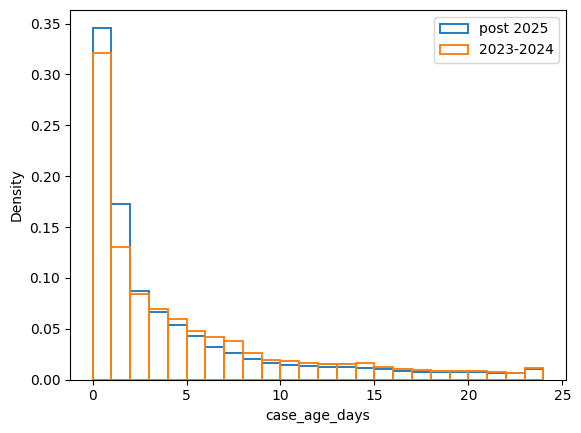

In [37]:
analysis_2025 = cat_df[cat_df['date_requested'] > '2025-01-01']
analysis_2023_2024 = year_df.copy()
sns.histplot(cat_df[cat_df['date_requested'] > '2025-01-01']['case_age_days'], bins = np.arange(0, 25), stat='density', label = 'post 2025', fill = False)
sns.histplot(year_df['case_age_days'], bins = np.arange(0, 25), stat='density', label = '2023-2024', fill = False)
plt.legend()

In [32]:
analysis_2025['case_age_days'].describe()


count    321227.000000
mean         13.194486
std          30.646264
min           0.000000
25%           0.000000
50%           2.000000
75%          10.000000
max         361.000000
Name: case_age_days, dtype: float64

In [33]:
analysis_2023_2024['case_age_days'].describe()

count    753888.000000
mean         19.278735
std          46.920036
min           0.000000
25%           0.000000
50%           3.000000
75%          13.000000
max         365.000000
Name: case_age_days, dtype: float64